# Event Study (Cumulative Abnormal Returns)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Lines up many events, such as earnings announcements, on a common clock (day 0 = event) and plots the average cumulative abnormal return (CAR): the return beyond what the market model predicts. A confidence band shows whether the reaction is distinguishable from noise. It is the standard way to measure how prices respond to news.

## When to use

- Measure the average price reaction to a type of event (earnings, dividends, rate decisions, index inclusion)
- Compare reactions between event groups (beats vs. misses, upgrades vs. downgrades)
- Check for information leakage before the event or drift after it

## Avoid when

- There are only a handful of events (the average is dominated by one case)
- Events overlap in time for the same stock (windows contaminate each other)
- Readers need the reaction of one specific event (plot that stock's returns instead)

## Alternatives

- Bar chart of day-0 abnormal return by group
- Small multiples of individual event paths

## Design tips

- Estimate the market model on a window that ends well before the event (e.g. days −250 to −30)
- Always show a confidence band; state n per group
- Mark day 0 and the zero line clearly

## Example

160 simulated earnings announcements (88 beats, 72 misses). Abnormal returns come from a market model estimated on days −250 to −30, and the event window is day −10 to +10. The simulation includes a small pre-announcement run-up and post-announcement drift. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(31)
n_events, est, win = 160, (-250, -30), np.arange(-10, 11)
beat = rng.random(n_events) < 0.6
rows = []
for e in range(n_events):
    days = np.arange(est[0], win[-1] + 1)
    mkt = rng.normal(0.0004, 0.010, len(days))
    beta_true, alpha_true = rng.uniform(0.7, 1.4), rng.normal(0, 0.0002)
    r = alpha_true + beta_true * mkt + rng.normal(0, 0.010, len(days))
    sign = 1 if beat[e] else -1
    r[days == 0] += sign * (0.025 if beat[e] else 0.030) + rng.normal(0, 0.012)
    r[(days > 0)] += sign * 0.0012                       # post-earnings drift
    r[(days >= -3) & (days < 0)] += sign * 0.0015        # small pre-event run-up
    rows.append(pd.DataFrame({"event": e, "day": days, "ret": r, "mkt": mkt,
                              "group": "Beat" if beat[e] else "Miss"}))
panel = pd.concat(rows, ignore_index=True)
panel.groupby("group")["event"].nunique()

group
Beat    88
Miss    72
Name: event, dtype: int64

### Plot

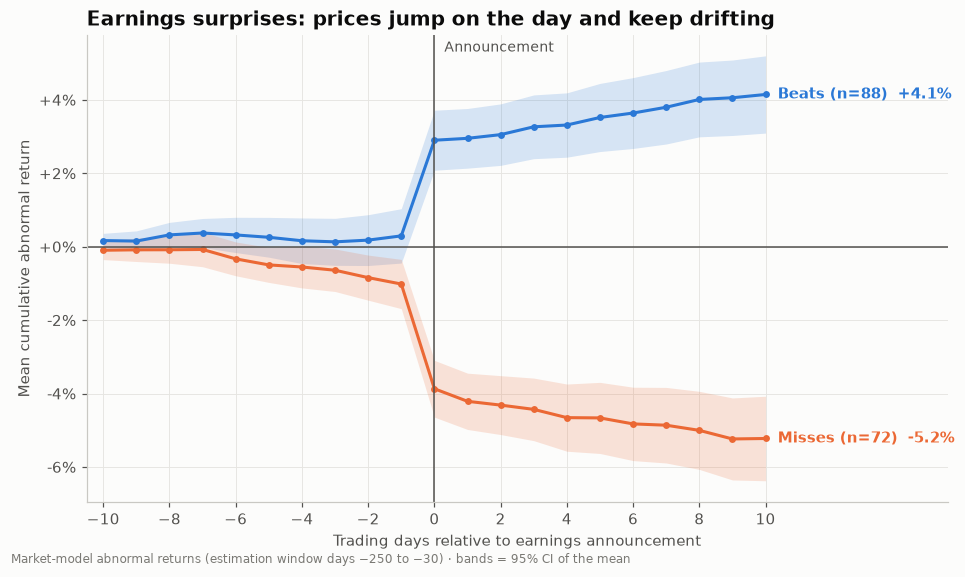

In [3]:
def car_paths(df):
    est_df = df[(df["day"] >= est[0]) & (df["day"] <= est[1])]
    b, a = np.polyfit(est_df["mkt"], est_df["ret"], 1)        # market model
    w = df[df["day"].isin(win)].sort_values("day")
    return (w["ret"] - (a + b * w["mkt"])).cumsum().values

fig, ax = plt.subplots(figsize=(9, 5.2))
for color, (group, g) in zip([PALETTE[0], PALETTE[1]], panel.groupby("group")):
    cars = np.vstack([car_paths(d) for _, d in g.groupby("event")])
    mean = cars.mean(axis=0)
    ci = 1.96 * cars.std(axis=0, ddof=1) / np.sqrt(len(cars))
    ax.fill_between(win, mean - ci, mean + ci, color=color, alpha=0.18, linewidth=0)
    ax.plot(win, mean, color=color, marker="o", markersize=3.5)
    ax.annotate(f"{group}{'es' if group.endswith('s') else 's'} (n={len(cars)})  {mean[-1]:+.1%}", (win[-1], mean[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=color, fontsize=10, fontweight="bold")
ax.axhline(0, color="#52514e", linewidth=1)
ax.axvline(0, color="#52514e", linewidth=1)
ax.text(0.3, ax.get_ylim()[1] * 0.92, "Announcement", fontsize=9, color="#52514e")
ax.set_xticks(win[::2])
ax.set_xlim(win[0] - 0.5, win[-1] + 5.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("Trading days relative to earnings announcement")
ax.set_ylabel("Mean cumulative abnormal return")
ax.set_title("Earnings surprises: prices jump on the day and keep drifting")
fig.text(0.01, 0.005, "Market-model abnormal returns (estimation window days −250 to −30) · bands = 95% CI of the mean",
         fontsize=8, color="#7a7974")
fig.tight_layout()
plt.show()

## How to read it

Both lines start near zero and split on day 0: beats (blue) jump up and misses (orange) drop, and both keep drifting in the same direction for days afterwards (post-earnings drift). The small moves just before day 0 hint at information leaking ahead of the release. The bands are 95% confidence intervals for the mean; after day 0 they no longer overlap, so the difference is unlikely to be chance.

---
Standalone script: [`event_study.py`](event_study.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)